### Installing required libraries

In [1]:
!pip install seaborn
!pip install missingno
!pip install xgboost
!pip install catboost
!pip install regex
!pip install scikit-learn
!pip install pandas
!pip install numpy
!pip install imblearn
!pip install lightgbm
!pip install polar


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached matplotlib-3.10.8-cp314-cp314-win_amd64.whl.metadata (52 kB)
  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached tzdata-2025.3-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached matplotlib-3.10.8-cp314-cp314-win_amd64.whl (8.3 MB)
Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl (232 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 54.1 MB/s  0:00:00
   ---------------------------------------- 0.0/12.4 MB ? eta -:--:--
   --------------------------------- ------ 10.5/12.4 MB 51.0 MB/s eta 0:00:01
   ---------------------------------------- 12.4/12.4 MB 

### Importing all libraries 

In [2]:
import pandas as pd   # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np   # linear algebra
import matplotlib.pyplot as plt  #graphs and plots
import seaborn as sns   #data visualizations 
import csv # Some extra functionalities for csv  files - reading it as a dictionary
from lightgbm import LGBMClassifier #sklearn is for machine learning and statistical modeling including classification, regression, clustering and dimensionality reduction 

from sklearn.model_selection import train_test_split, cross_validate   #break up dataset into train and test sets

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# importing python library for working with missing data
import missingno as msno
# To install missingno use: !pip install missingno
import re    # This library is used to perform regex pattern matching

# import various functions from sklearn
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import GradientBoostingClassifier
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, classification_report, make_scorer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

### Import additional items as needed...

In [4]:
from sklearn.model_selection import KFold,cross_val_score, RepeatedStratifiedKFold,StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import OneHotEncoder,StandardScaler,PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.compose import make_column_transformer
from imblearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score,\
                            precision_score, recall_score, roc_auc_score,\
                            classification_report, f1_score # removed plot_roc_curve and plot_confusion_matrix as they are deprecated

import plotly 
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

import warnings
warnings.filterwarnings("ignore")

### Loading CSV data 

In [3]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# DATA EXPLORATION

In [5]:
diabetes.head(30)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
diabetes.shape

(101766, 50)

In [7]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')

In [8]:
diabetes.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [9]:
# placing the percentage of missing values in each column in a dataframe
missing_pct = (diabetes.isna()
                          .mean()
                          .mul(100)
                          .round(2)
                         # .sort_values(ascending=False)  #remove the # to sort by percentage of missing values in descending order
                          .reset_index())

missing_pct.columns = ["column", "percent_missing"]
missing_pct

,column,percent_missing
0,encounter_id,0.00
1,patient_nbr,0.00
2,race,0.00
3,gender,0.00
4,age,0.00
5,weight,0.00
6,admission_type_id,0.00
7,discharge_disposition_id,0.00
8,admission_source_id,0.00
9,time_in_hospital,0.00


<Axes: >

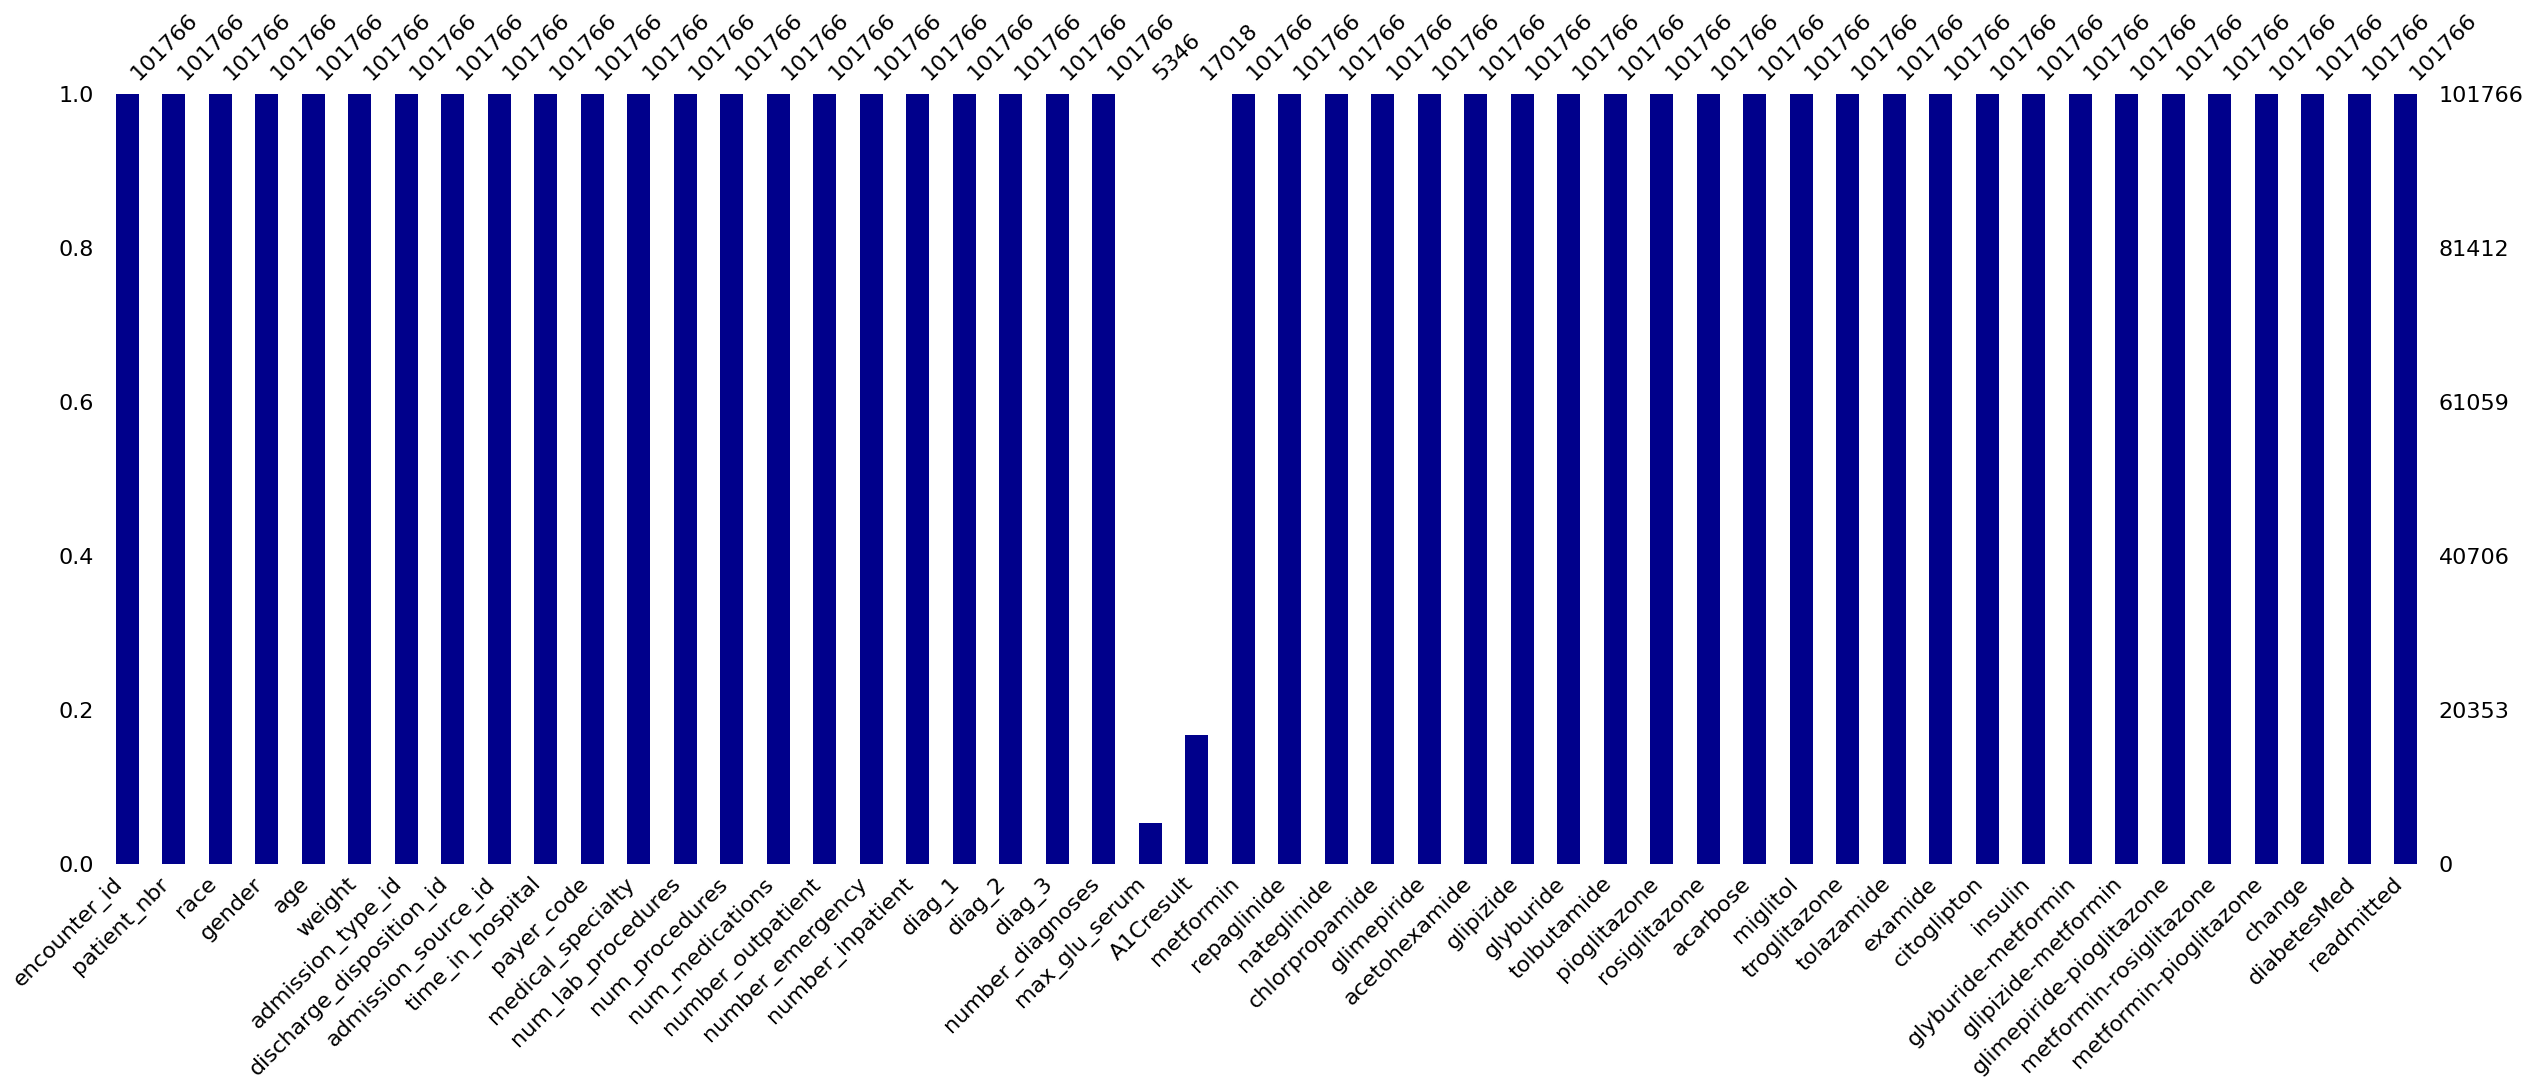

In [10]:
# visualizing the percentage of missing values in each column
msno.bar(diabetes, figsize=(30, 10), color='darkblue')

In [11]:
# Number of unique patients
unique_patients = diabetes['patient_nbr'].nunique()
print(f"Number of unique patients: {unique_patients}")

# Number of unique hospital encounters
unique_encounters = diabetes['encounter_id'].nunique()
print(f"Total number of hospital admissions: {unique_encounters}")

# Count admissions per patient
admissions_per_patient = (
    diabetes['patient_nbr']
    .value_counts()
    .rename_axis('patient_nbr')
    .reset_index(name='admission_count')
)

# Patients with more than one admission
multiple_admissions = admissions_per_patient.query("admission_count > 1")

# Proportion of patients with multiple admissions
prop_multiple = multiple_admissions['patient_nbr'].nunique() / unique_patients
print(f"Proportion of patients that have multiple admissions: {prop_multiple:.2%}")

# Maximum number of admissions for any patient
max_admissions = admissions_per_patient['admission_count'].max()
print(f"Highest number of admissions recorded for a single patient: {max_admissions}")

Number of unique patients: 71518
Total number of hospital admissions: 101766
Proportion of patients that have multiple admissions: 23.45%
Highest number of admissions recorded for a single patient: 40


# MAIN VARIABLE SELECTION

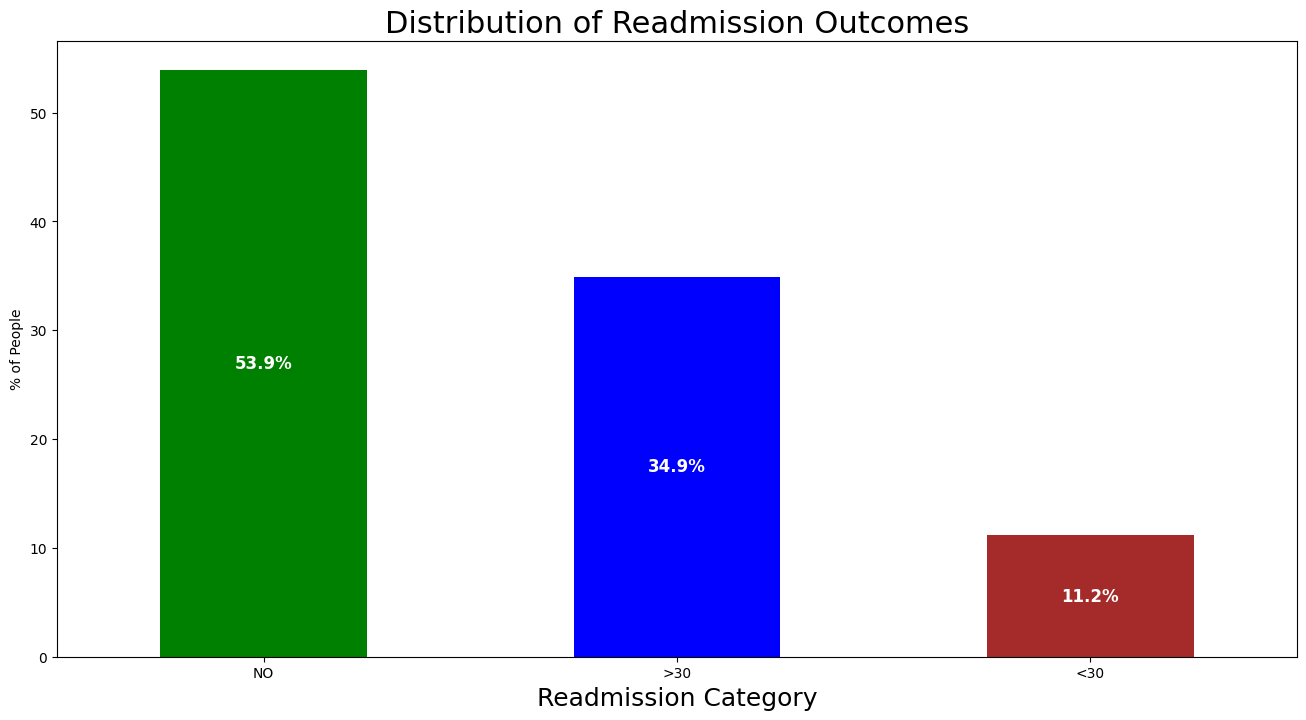

In [12]:
# Distribution of the readmitted variable
df_outcome = diabetes["readmitted"].value_counts(normalize=True) * 100

# Plot
plt.figure(figsize=(16, 8))
ax = df_outcome.plot(
    kind='bar',
    stacked=True,
    color=['green', 'blue', 'brown'],
)

plt.ylabel('% of People')
plt.xlabel('Readmission Category',fontsize=18)
plt.title('Distribution of Readmission Outcomes',fontsize=22)
plt.xticks(rotation=0)

# Add % labels inside each bar
for i, value in enumerate(df_outcome):
    ax.text(
        i,                      # x-position (bar index)
        value / 2,              # y-position (middle of the bar)
        f"{value:.1f}%",        # label text
        ha='center', va='center',
        color='white', fontsize=12, fontweight='bold'
    )

plt.show()

In [13]:
#@title READMITTED ENCODING ALL READMISSIONS
# Mapping for readmission categories
readmitted_map = {
    "NO": 0,
    "<30": 1,
    ">30": 1
}

# Create a NEW column instead of overwriting the original
diabetes['all_readmission'] = diabetes['readmitted'].map(readmitted_map)

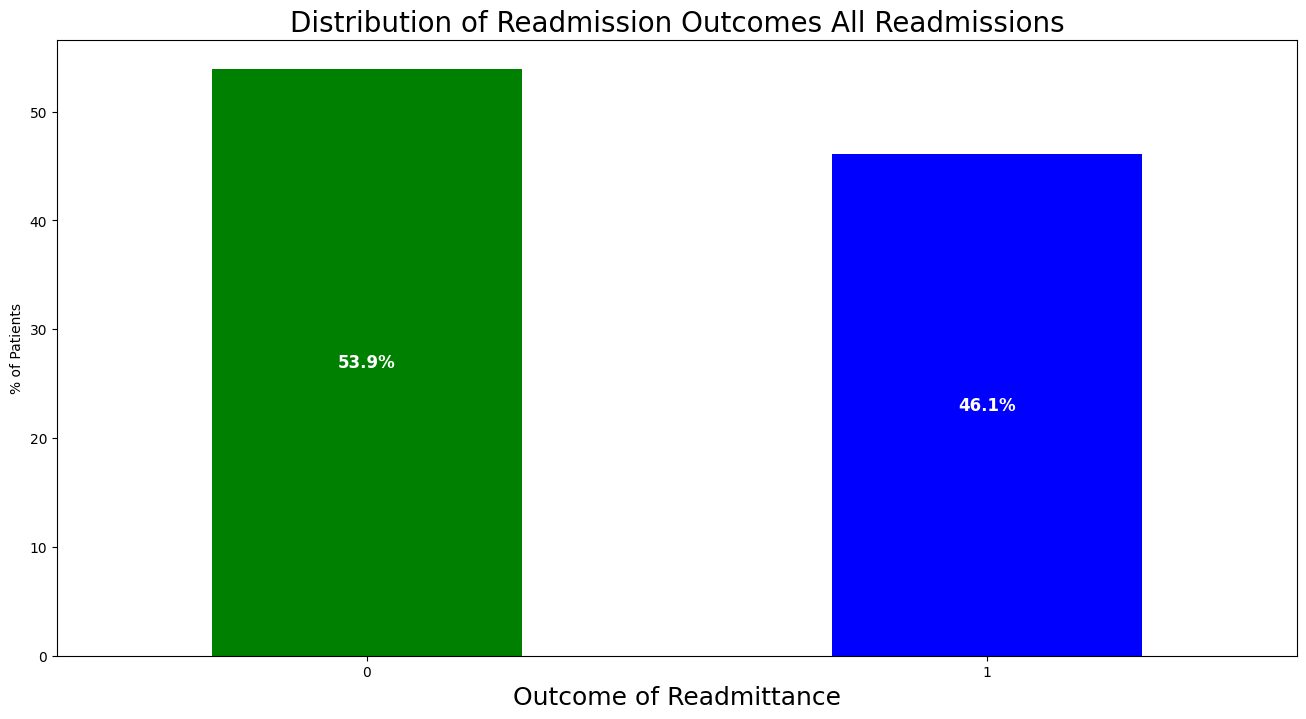

In [14]:
# Distribution of the readmitted variable
df_outcome = diabetes["all_readmission"].value_counts(normalize=True) * 100

# Plot
plt.figure(figsize=(16, 8))
ax = df_outcome.plot(
    kind='bar',
    color=['green', 'blue'], 
    stacked=True,
    figsize=(16, 8)
)

plt.xlabel('Outcome of Readmittance', fontsize=18)
plt.ylabel('% of Patients')
plt.title('Distribution of Readmission Outcomes All Readmissions', fontsize=20)
plt.xticks(rotation=0)

# Add % labels inside each bar
for i, value in enumerate(df_outcome):
    ax.text(
        i,                      # x-position (bar index)
        value / 2,              # y-position (middle of the bar)
        f"{value:.1f}%",        # label text
        ha='center', va='center',
        color='white', fontsize=12, fontweight='bold'
    )

plt.show()


In [15]:
#@title READMITTED ENCODING LESS THAN 30 DAYS
# # Mapping for readmission categories
readmitted_map = {
    "NO": 0,
    "<30": 1,
    ">30": 0
}

# Create a NEW column instead of overwriting the original
diabetes['lessthan30'] = diabetes['readmitted'].map(readmitted_map)

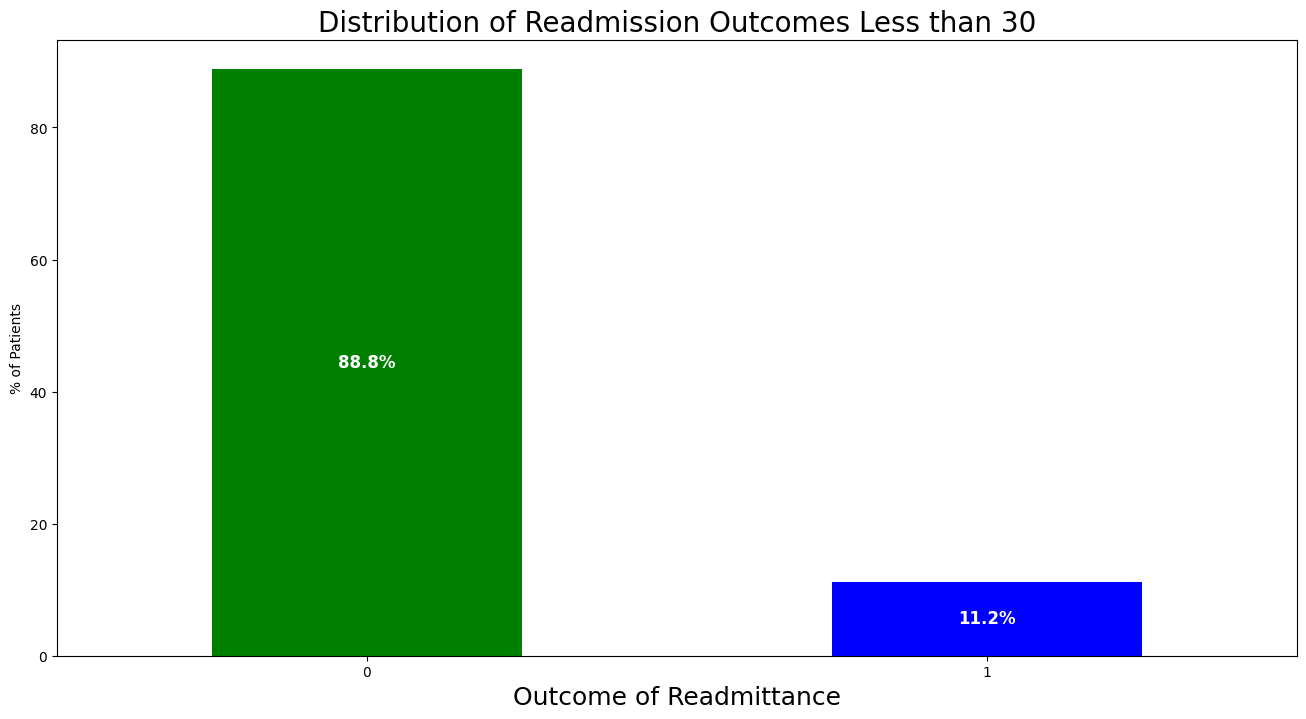

In [16]:
# Distribution of the readmitted variable
df_outcome = diabetes["lessthan30"].value_counts(normalize=True) * 100

# Plot
plt.figure(figsize=(16, 8))
ax = df_outcome.plot(
    kind='bar',
    color=['green', 'blue'], 
    stacked=True,
    figsize=(16, 8)
)

plt.xlabel('Outcome of Readmittance', fontsize=18)
plt.ylabel('% of Patients')
plt.title('Distribution of Readmission Outcomes Less than 30', fontsize=20)
plt.xticks(rotation=0)

# Add % labels inside each bar
for i, value in enumerate(df_outcome):
    ax.text(
        i,                      # x-position (bar index)
        value / 2,              # y-position (middle of the bar)
        f"{value:.1f}%",        # label text
        ha='center', va='center',
        color='white', fontsize=12, fontweight='bold'
    )

plt.show()

# CLEANING AND TRANSFORMING THE DATASET

In [17]:
#@title GENDER ENCODING
# Keep only Male and Female rows
diabetes = diabetes[diabetes['gender'].isin(['Male', 'Female'])].copy()

# Create indicator: 1 = Male, 0 = Female
diabetes['GenderMale'] = (diabetes['gender'] == 'Male').astype(int)

In [18]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [19]:
#@title ER/URGENT CARE ADMISSION CODING
# Created a new column ERAdmission.
# ERAdmission = 1 if admission_type_id is 1 or 2 (Emergency/Urgent), otherwise 0.

diabetes['ERAdmission'] = diabetes['admission_type_id'].isin([1, 2]).astype(int)

In [20]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 0 if x == "No" else 1
)

In [21]:
#@title RACE ENCODING
diabetes['RaceCaucasian'] = (diabetes['race'] == 'Caucasian').astype(int)
diabetes['RaceAfricanAmerican'] = (diabetes['race'] == 'AfricanAmerican').astype(int)
diabetes['RaceOther'] = (~diabetes['race'].isin(['Caucasian', 'AfricanAmerican'])).astype(int)

In [22]:
#@title ICD-9 CATEGORIZATION
# 1. Map ICD-9 codes
def categorize_icd9_chapter(code):
    """Maps ICD-9 codes to 17 main chapters + 2 supplemental categories"""
    if pd.isna(code):
        return "Missing"

    code_str = str(code).strip()

    # Supplemental codes
    if code_str.startswith('V'):
        return "V-codes: Factors Influencing Health Status"
    if code_str.startswith('E'):
        return "E-codes: External Causes of Injury"

    # Extract numeric part
    try:
        numeric_part = ''.join(filter(str.isdigit, code_str))
        if not numeric_part:
            return "Unmapped"
        code_num = int(numeric_part[:3])
    except:
        return "Unmapped"

    # ICD-9 chapter ranges
    chapter_map = {
        range(1, 140): "Infectious and Parasitic Diseases",
        range(140, 240): "Neoplasms (Cancers/Tumors)",
        range(240, 280): "Endocrine, Nutritional, Metabolic Diseases",
        range(280, 290): "Diseases of Blood and Blood-forming Organs",
        range(290, 320): "Mental Disorders",
        range(320, 390): "Diseases of Nervous System and Sense Organs",
        range(390, 460): "Diseases of Circulatory System",
        range(460, 520): "Diseases of Respiratory System",
        range(520, 580): "Diseases of Digestive System",
        range(580, 630): "Diseases of Genitourinary System",
        range(630, 680): "Complications of Pregnancy, Childbirth, Puerperium",
        range(680, 710): "Diseases of Skin and Subcutaneous Tissue",
        range(710, 740): "Diseases of Musculoskeletal System and Connective Tissue",
        range(740, 760): "Congenital Anomalies",
        range(760, 780): "Conditions Originating in Perinatal Period",
        range(780, 800): "Symptoms, Signs, Ill-defined Conditions",
        range(800, 1000): "Injury and Poisoning"
    }

    for code_range, chapter_name in chapter_map.items():
        if code_num in code_range:
            return chapter_name

    return "Unmapped"


In [23]:
#@title CATEGORIZING PRIMARY DIAGNOSIS
# Applying categorization the priamry diagnosis column diag_1
diabetes['Primary_Diagnosis'] = diabetes['diag_1'].apply(categorize_icd9_chapter)
print("Created diag_1_chapter")

print("\nChapter Distribution for Primary Diagnosis (diag_1_chapter):")
print(diabetes['Primary_Diagnosis'].value_counts().head(20))


Created diag_1_chapter

Chapter Distribution for Primary Diagnosis (diag_1_chapter):
Primary_Diagnosis
Diseases of Circulatory System                              30335
Endocrine, Nutritional, Metabolic Diseases                  11459
Diseases of Respiratory System                              10407
Diseases of Digestive System                                 9208
Symptoms, Signs, Ill-defined Conditions                      7636
Injury and Poisoning                                         6972
Diseases of Genitourinary System                             5078
Diseases of Musculoskeletal System and Connective Tissue     4957
Neoplasms (Cancers/Tumors)                                   3433
Infectious and Parasitic Diseases                            2768
Diseases of Skin and Subcutaneous Tissue                     2530
Mental Disorders                                             2262
V-codes: Factors Influencing Health Status                   1644
Diseases of Nervous System and Sense Or

In [24]:
#@title DIABETES RELATED DIAGNOSIS INDICATOR
diabetes['PDX_diabetes_related'] = diabetes['Primary_Diagnosis'].str.contains(
    'Endocrine', case=False, na=False
).astype(int)


In [25]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'all_readmission', 'lessthan30', 'GenderMale', 'ERAdmission',
       'RaceCaucasian',

In [26]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'race', 'weight', 'gender',
    'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
    'payer_code', 'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'max_glu_serum', 'A1Cresult',
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
    'tolazamide', 'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone',
    'change', 'readmitted', 'Primary_Diagnosis'
], axis=1)

In [27]:
cleandiabetes.head()

,encounter_id,patient_nbr,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,all_readmission,lessthan30,GenderMale,ERAdmission,RaceCaucasian,RaceAfricanAmerican,RaceOther,PDX_diabetes_related
0,2278392,8222157,5,1,41,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1
1,149190,55629189,15,3,59,0,18,0,0,0,9,1,1,0,0,1,1,0,0,1
2,64410,86047875,25,2,11,5,13,2,0,1,6,1,0,0,0,1,0,1,0,0
3,500364,82442376,35,2,44,1,16,0,0,0,7,1,0,0,1,1,1,0,0,0
4,16680,42519267,45,1,51,0,8,0,0,0,5,1,0,0,1,1,1,0,0,0


### FINALIZING DATASET

In [28]:
# Unique and duplicate patient IDs based on patient_nbr
unique_ids = cleandiabetes['patient_nbr'].unique()
duplicate_ids = cleandiabetes['patient_nbr'][cleandiabetes['patient_nbr'].duplicated()].unique()

print(f"Cleaned diabetes dataset size: {len(cleandiabetes)}")
print(f"Total number of unique patient IDs in cleandiabetes: {len(unique_ids)}")
print(f"Total number of duplicate patient IDs in cleandiabetes: {len(duplicate_ids)}")


Cleaned diabetes dataset size: 101763
Total number of unique patient IDs in cleandiabetes: 71515
Total number of duplicate patient IDs in cleandiabetes: 16773


In [29]:
#removing primary_diagnosis column as they are not relevant to our analysis
cols_to_drop = ['encounter_id', 'patient_nbr']

subcleanDB = cleandiabetes.drop(columns=cols_to_drop)

In [30]:
subcleanDB.columns

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed',
       'all_readmission', 'lessthan30', 'GenderMale', 'ERAdmission',
       'RaceCaucasian', 'RaceAfricanAmerican', 'RaceOther',
       'PDX_diabetes_related'],
      dtype='str')

In [31]:
numerical = ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses' ]

### MISSING DATA

In [32]:
def missing(subcleanDB):
    missing_number = subcleanDB.isnull().sum().sort_values(ascending=False)
    missing_percent = (subcleanDB.isnull().sum() / subcleanDB.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [33]:
print("Missing Data in subcleanDB:")
display(missing(subcleanDB))

Missing Data in subcleanDB:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0


### VISUALING MISSING DATA

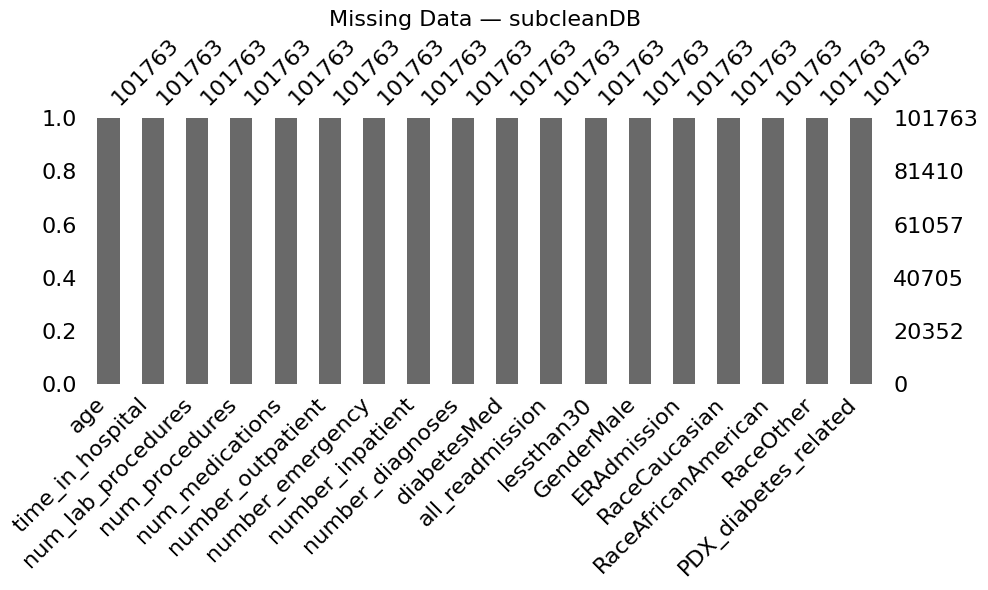

In [34]:
# Visualizing the missing data to get more idea
fig, ax = plt.subplots(figsize=(10, 6))

msno.bar(subcleanDB, ax=ax)
ax.set_title("Missing Data — subcleanDB", fontsize=16)

plt.tight_layout()
plt.show()

### CORRELATION

In [35]:
#@title Correlation Matrices
print("Correlation Matrix for subcleanDB")
display(subcleanDB[numerical].corr())

Correlation Matrix for subcleanDB


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
age,1.000000,0.107516,0.020777,-0.030119,0.041839,0.023727,-0.087289,-0.042856,0.242609
time_in_hospital,0.107516,1.000000,0.318429,0.191497,0.466137,-0.008919,-0.009683,0.073619,0.220153
num_lab_procedures,0.020777,0.318429,1.000000,0.058105,0.268176,-0.007606,-0.002282,0.039225,0.152737
num_procedures,-0.030119,0.191497,0.058105,1.000000,0.385761,-0.024813,-0.038175,-0.066226,0.073769
num_medications,0.041839,0.466137,0.268176,0.385761,1.000000,0.045198,0.013180,0.064196,0.261529
number_outpatient,0.023727,-0.008919,-0.007606,-0.024813,0.045198,1.000000,0.091457,0.107334,0.094148
number_emergency,-0.087289,-0.009683,-0.002282,-0.038175,0.013180,0.091457,1.000000,0.266557,0.055536
number_inpatient,-0.042856,0.073619,0.039225,-0.066226,0.064196,0.107334,0.266557,1.000000,0.104703
number_diagnoses,0.242609,0.220153,0.152737,0.073769,0.261529,0.094148,0.055536,0.104703,1.000000


In [36]:
print("Correlation for subcleanDB grouped by all_readmission")
corr_all = subcleanDB.groupby('all_readmission')[numerical].corr()
display(corr_all)

print("\nCorrelation for subcleanDB grouped by lessthan30")
corr_30 = subcleanDB.groupby('lessthan30')[numerical].corr()
display(corr_30)

Correlation for subcleanDB grouped by all_readmission


age  time_in_hospital  \
all_readmission                                                  
0               age                 1.000000          0.144615   
                time_in_hospital    0.144615          1.000000   
                num_lab_procedures  0.046912          0.336104   
                num_procedures     -0.031601          0.175227   
                num_medications     0.068920          0.463081   
                number_outpatient   0.031403         -0.015867   
                number_emergency   -0.024301         -0.000691   
                number_inpatient    0.058477          0.090365   
                number_diagnoses    0.278984          0.236415   
1               age                 1.000000          0.059833   
                time_in_hospital    0.059833          1.000000   
                num_lab_procedures -0.014219          0.294811   
                num_procedures     -0.025223          0.217432   
                num_medications     0.002719          0.468306   
                number_outpatient   0.013613         -0.011427   
                number_emergency   -0.138222         -0.023905   
                number_inpatient   -0.128776          0.051430   
                number_diagnoses    0.189070          0.190618   

                                    num_lab_procedures  num_procedures  \
all_readmission                                                          
0               age                           0.046912       -0.031601   
                time_in_hospital              0.336104        0.175227   
                num_lab_procedures            1.000000        0.048453   
                num_procedures                0.048453        1.000000   
                num_medications               0.256426        0.410067   
                number_outpatient            -0.032017       -0.020219   
                number_emergency             -0.004583       -0.046687   
                number_inpatient              0.038857       -0.053848   
                number_diagnoses              0.161072        0.071108   
1               age                          -0.014219       -0.025223   
                time_in_hospital              0.294811        0.217432   
                num_lab_procedures            1.000000        0.074300   
                num_procedures                0.074300        1.000000   
                num_medications               0.280664        0.360304   
                number_outpatient             0.006139       -0.022928   
                number_emergency             -0.008091       -0.031961   
                number_inpatient              0.028909       -0.065506   
                number_diagnoses              0.134257        0.090830   

                                    num_medications  number_outpatient  \
all_readmission                                                          
0               age                        0.068920           0.031403   
                time_in_hospital           0.463081          -0.015867   
                num_lab_procedures         0.256426          -0.032017   
                num_procedures             0.410067          -0.020219   
                num_medications            1.000000           0.032120   
                number_outpatient          0.032120           1.000000   
                number_emergency           0.010865           0.099985   
                number_inpatient           0.054702           0.086905   
                number_diagnoses           0.257425           0.087450   
1               age                        0.002719           0.013613   
                time_in_hospital           0.468306          -0.011427   
                num_lab_procedures         0.280664           0.006139   
                num_procedures             0.360304          -0.022928   
                num_medications            1.000000           0.051850   
                number_outpatient          0.051850    


Correlation for subcleanDB grouped by lessthan30


age  time_in_hospital  num_lab_procedures  \
lessthan30                                                                      
0          age                 1.000000          0.110389            0.023679   
           time_in_hospital    0.110389          1.000000            0.317966   
           num_lab_procedures  0.023679          0.317966            1.000000   
           num_procedures     -0.030493          0.184436            0.052939   
           num_medications     0.045632          0.463447            0.263577   
           number_outpatient   0.025841         -0.008027           -0.009679   
           number_emergency   -0.073725         -0.003929            0.004752   
           number_inpatient   -0.012439          0.081365            0.044138   
           number_diagnoses    0.250586          0.222743            0.153452   
1          age                 1.000000          0.078964           -0.006361   
           time_in_hospital    0.078964          1.000000            0.317655   
           num_lab_procedures -0.006361          0.317655            1.000000   
           num_procedures     -0.025012          0.256572            0.104734   
           num_medications     0.005392          0.479381            0.300945   
           number_outpatient   0.004394         -0.022948            0.005296   
           number_emergency   -0.171721         -0.054951           -0.046064   
           number_inpatient   -0.209974          0.011970            0.004974   
           number_diagnoses    0.167476          0.182704            0.138825   

                               num_procedures  num_medications  \
lessthan30                                                       
0          age                      -0.030493         0.045632   
           time_in_hospital          0.184436         0.463447   
           num_lab_procedures        0.052939         0.263577   
           num_procedures            1.000000         0.385402   
           num_medications           0.385402         1.000000   
           number_outpatient        -0.023116         0.044064   
           number_emergency         -0.036941         0.017059   
           number_inpatient         -0.063103         0.066991   
           number_diagnoses          0.071891         0.261232   
1          age                      -0.025012         0.005392   
           time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_outpatient        -0.036554         0.048016   
           number_emergency         -0.044692        -0.019015   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   

                               number_outpatient  number_emergency  \
lessthan30                                                           
0          age                          0.025841         -0.073725   
           time_in_hospital            -0.008027         -0.003929   
           num_lab_procedures          -0.009679          0.004752   
           num_procedures              -0.023116         -0.036941   
           num_medications              0.044064          0.017059   
           number_outpatient            1.000000          0.091213   
           number_emergency             0.091213          1.000000   
           number_inpatient             0.106594          0.241276   
           number_diagnoses             0.093655          0.056898   
1          age                          0.004394         -0.171721   
           time_in_hospital            -0.022948         -0.054951   
           num_lab_procedures           0.005296         -0.046064   
           num_procedures              -0.036554         -0.044692   
           num_medications              0.04

| Color Range      | Intensity    | Correlation         | Meaning                                    |
| ---------------- | ------------ | ------------------- | ------------------------------------------ |
| Dark Red         | 0.6 to 1.0   | Strong positive     | Variables move together (both ↑ or both ↓) |
| Light Red/Orange | 0.2 to 0.6   | Moderate positive   | Variables tend to move together            |
| White/Pale       | -0.2 to +0.2 | Weak/No correlation | No linear relationship                     |
| Light Blue       | -0.2 to -0.6 | Moderate negative   | Variables move opposite (one ↑, other ↓)   |
| Dark Blue        | -0.6 to -1.0 | Strong negative     | Variables strongly oppose each other       |

|CORRELATION| ACTION                      |
|-----------|-----------------------------|
| ≥ +0.70   | Feature engineering/PCA     |
| +0.50-0.69| Keep both (important pair)  |
| +0.30-0.49| Moderate (conditional keep) |
| < ±0.30   | Weak (consider dropping)    |


In [37]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


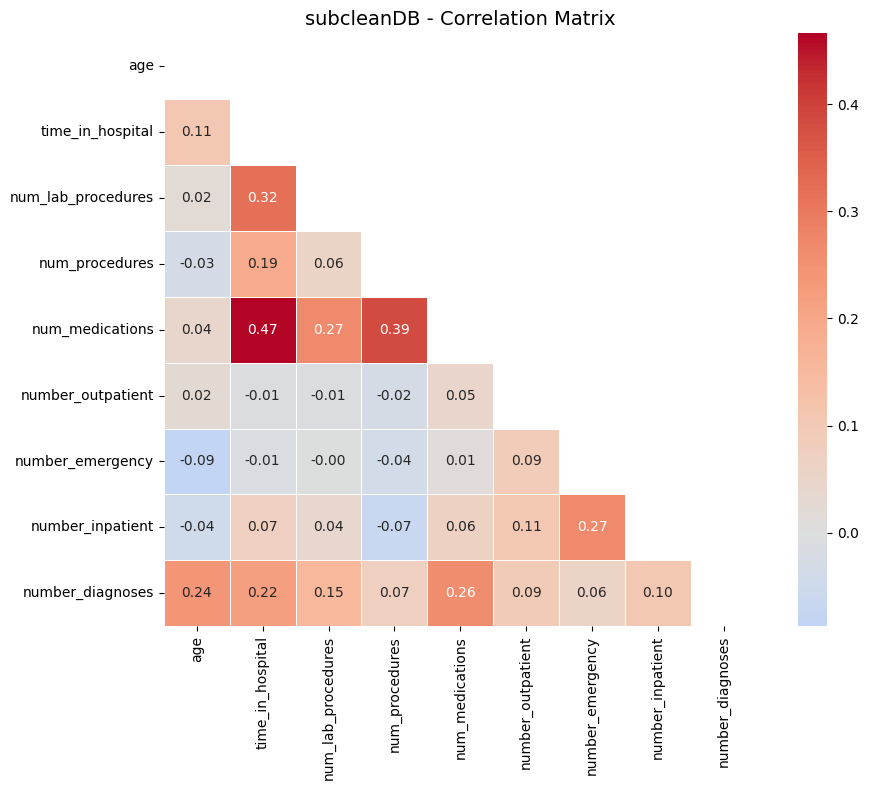

In [38]:
plot_corr_heatmap(subcleanDB, numerical, "subcleanDB - Correlation Matrix")

In [38]:
print("subcleanDB correlation (time_in_hospital vs all_readmission)")
display(subcleanDB[['time_in_hospital', 'all_readmission']].corr())

print("\nsubcleanDB correlation (time_in_hospital vs lessthan30)")
display(subcleanDB[['time_in_hospital', 'lessthan30']].corr())

subcleanDB correlation (time_in_hospital vs all_readmission)


,time_in_hospital,all_readmission
time_in_hospital,1.000000,0.051281
all_readmission,0.051281,1.000000



subcleanDB correlation (time_in_hospital vs lessthan30)


,time_in_hospital,lessthan30
time_in_hospital,1.000000,0.044197
lessthan30,0.044197,1.000000


## Breaking the data up into Train & Test

In [39]:
#@title Setting Up Data for Modeling 
DataTesting = subcleanDB.copy() 

In [40]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71234
Validation size: 15264
Test size: 15265
Total: 101763


In [41]:
datasets = {
    "DataTesting": DataTesting,
    "Train": train_df,
    "Valid": valid_df,
    "Test": test_df
}

for name, df in datasets.items():
    print(f"\n===== {name} Dataset =====")
    
    # all_readmission counts
    print("all_readmission:")
    print(df["all_readmission"].value_counts())
    
    # lessthan30 counts
    print("\nlessthan30:")
    print(df["lessthan30"].value_counts())



===== DataTesting Dataset =====
all_readmission:
all_readmission
0    54861
1    46902
Name: count, dtype: int64

lessthan30:
lessthan30
0    90406
1    11357
Name: count, dtype: int64

===== Train Dataset =====
all_readmission:
all_readmission
0    38485
1    32749
Name: count, dtype: int64

lessthan30:
lessthan30
0    63318
1     7916
Name: count, dtype: int64

===== Valid Dataset =====
all_readmission:
all_readmission
0    8207
1    7057
Name: count, dtype: int64

lessthan30:
lessthan30
0    13519
1     1745
Name: count, dtype: int64

===== Test Dataset =====
all_readmission:
all_readmission
0    8169
1    7096
Name: count, dtype: int64

lessthan30:
lessthan30
0    13569
1     1696
Name: count, dtype: int64


## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [42]:
def balance_random_oversample(df, targets=['all_readmission', 'lessthan30'], random_state=42):
    balanced_results = {}

    for target in targets:
        if target not in df.columns:
            print(f"WARNING: Target '{target}' not found in dataframe. Skipping.")
            continue

        # Split positive and negative classes
        df_pos = df[df[target] == 1]
        df_neg = df[df[target] == 0]

        # Oversample minority class
        df_pos_over = resample(
            df_pos,
            replace=True,
            n_samples=len(df_neg),
            random_state=random_state
        )

        # Combine and shuffle
        df_bal = (
            pd.concat([df_neg, df_pos_over])
            .sample(frac=1, random_state=random_state)
            .reset_index(drop=True)
        )

        balanced_results[target] = df_bal

    return balanced_results


#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [43]:
def balance_smote(df, targets=['all_readmission', 'lessthan30'], random_state=42):
    balanced_results = {}

    for target in targets:
        if target not in df.columns:
            print(f"WARNING: Target '{target}' not found in dataframe. Skipping.")
            continue

        # Split X and y
        X = df.drop(columns=[target])
        y = df[target]

        # Apply SMOTE
        sm = SMOTE(random_state=random_state)
        X_res, y_res = sm.fit_resample(X, y)

        # Rebuild balanced dataframe
        df_bal = pd.concat(
            [pd.DataFrame(X_res, columns=X.columns),
             pd.Series(y_res, name=target)],
            axis=1
        )

        balanced_results[target] = df_bal

    return balanced_results


#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [44]:
def balance_random_undersample(df, targets=['all_readmission', 'lessthan30'], random_state=42):
    balanced_results = {}

    for target in targets:
        if target not in df.columns:
            print(f"WARNING: Target '{target}' not found in dataframe. Skipping.")
            continue

        # Split positive and negative classes
        df_pos = df[df[target] == 1]
        df_neg = df[df[target] == 0]

        # Undersample majority class
        df_neg_under = df_neg.sample(
            n=len(df_pos),
            random_state=random_state
        )

        # Combine and shuffle
        df_bal = (
            pd.concat([df_pos, df_neg_under])
            .sample(frac=1, random_state=random_state)
            .reset_index(drop=True)
        )

        balanced_results[target] = df_bal

    return balanced_results


#### Prevalence Caculation Function

In [45]:
def calc_prevalence(y_actual):
    """
    Calculate prevalence (proportion of positive class = 1)
    for a binary target Series or array.
    """
    y = pd.Series(y_actual)

    # Safety check: ensure binary values
    unique_vals = set(y.dropna().unique())
    if not unique_vals.issubset({0, 1}):
        raise ValueError(f"Non-binary values found in target: {unique_vals}")

    return y.mean()


<h2 style="color:#e63946;">IMBALANCE TECHNIQUE USED</h2>

In [65]:
# ============================================================
#  Define available balancing methods
# ============================================================

balancers = {
    "SMOTE": balance_smote,
    "Random Oversample": balance_random_oversample,
    "Random Undersample": balance_random_undersample
}

# ============================================================
#  Choose which balancing method to use
# ============================================================

chosen_method = "Random Undersample"   # <-- change this anytime
chosen_balancer = balancers[chosen_method]

print(f"\n===== USING BALANCING METHOD: {chosen_method} =====")

# ============================================================
#  Apply the chosen method (returns dict of balanced datasets)
# ============================================================

train_balanced = chosen_balancer(train_df)

# ============================================================
#  Print results for each target separately
# ============================================================

for target in ['all_readmission', 'lessthan30']:

    if target not in train_balanced:
        print(f"\n❌ ERROR: '{target}' not found in balanced output")
        print(f"Available keys: {list(train_balanced.keys())}")
        continue

    df_bal = train_balanced[target]

    print("\n" + "="*50)
    print(f" BALANCED DATA SUMMARY — {target} ")
    print("="*50)
    print(f"Balanced size: {len(df_bal)}")

    prev = calc_prevalence(df_bal[target])
    print(f"Prevalence: {prev:.3f}")
    print("="*50 + "\n")



===== USING BALANCING METHOD: Random Undersample =====

 BALANCED DATA SUMMARY — all_readmission 
Balanced size: 65498
Prevalence: 0.500


 BALANCED DATA SUMMARY — lessthan30 
Balanced size: 15832
Prevalence: 0.500



In [66]:
targets = ['all_readmission', 'lessthan30']

splits = {}

for target in targets:

    # safety check
    if target not in train_balanced:
        print(f"\n❌ ERROR: '{target}' not found in train_balanced")
        print(f"Available keys: {list(train_balanced.keys())}")
        continue

    df_bal = train_balanced[target]

    splits[target] = {
        "X_train": df_bal.drop(columns=[target]),
        "y_train": df_bal[target],

        "X_valid": valid_df.drop(columns=[target]),
        "y_valid": valid_df[target],

        "X_test": test_df.drop(columns=[target]),
        "y_test": test_df[target],
    }

    print(f"\n✅ Successfully created splits for: {target}")



✅ Successfully created splits for: all_readmission

✅ Successfully created splits for: lessthan30


## Scaler configurations.


In [68]:
Set1 = ['age', 
          'time_in_hospital', 
          'num_lab_procedures', 
          'num_procedures',
          'num_medications', 
          'number_outpatient', 
          'number_emergency',
          'number_inpatient', 
          'number_diagnoses', 
          'diabetesMed',
          'GenderMale', 
          'ERAdmission',
          'RaceCaucasian', 
          'RaceAfricanAmerican', 
          'RaceOther',
          'PDX_diabetes_related'
       ]


<h2 style="color:#e63946;">SCALER</h2>

In [69]:
scale_cols = Set1   # your list of columns to scale

scalers = {}        # store one scaler per target

for target in ['all_readmission', 'lessthan30']:
    # pull the X splits for this target
    X_train = splits[target]['X_train']
    X_valid = splits[target]['X_valid']
    X_test  = splits[target]['X_test']

    # create and fit scaler on TRAIN ONLY
    scaler = StandardScaler()
    X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

    # transform valid + test
    X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
    X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

    # save scaled data back into splits
    splits[target]['X_train'] = X_train
    splits[target]['X_valid'] = X_valid
    splits[target]['X_test']  = X_test

    # store scaler in case you want to use it later
    scalers[target] = scaler


In [70]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,all_readmission,GenderMale,ERAdmission,RaceCaucasian,RaceAfricanAmerican,RaceOther,PDX_diabetes_related
0,0.551210,-0.854636,-0.739282,-0.186526,-1.162041,-0.304679,-0.217181,-0.552061,-0.285583,-1.902573,0,1.085089,-1.592575,0.565290,-0.476946,-0.245506,-0.371608
1,-1.333755,-0.519952,0.592447,-0.785650,0.445251,0.432323,-0.217181,0.686633,0.788883,0.525604,1,1.085089,0.627914,0.565290,-0.476946,-0.245506,-0.371608
2,-1.333755,-0.519952,1.411973,-0.785650,-0.791128,-0.304679,-0.217181,-0.552061,-2.434516,-1.902573,1,-0.921584,-1.592575,-1.769002,-0.476946,4.073219,-0.371608
3,-0.077111,-1.189319,-1.712469,0.412598,0.074337,0.432323,-0.217181,0.067286,0.251650,0.525604,1,-0.921584,-1.592575,0.565290,-0.476946,-0.245506,-0.371608
4,0.551210,-0.854636,0.182684,-0.785650,0.197975,-0.304679,-0.217181,0.686633,0.788883,0.525604,1,-0.921584,0.627914,0.565290,-0.476946,-0.245506,-0.371608


## Creating and Understanding Models

In [71]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [72]:
np.set_printoptions(threshold=np.inf)

models = {}
predictions = {}

for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']

    # train model
    lnr = LinearRegression()
    lnr.fit(X_train, y_train)

    # store model
    models[target] = lnr

    # predict on validation
    y_valid_preds = lnr.predict(X_valid)
    predictions[target] = y_valid_preds

    print(f"\n===== Linear Regression for {target} =====")
    print("First 10 predictions:", y_valid_preds[:10])



===== Linear Regression for all_readmission =====
First 10 predictions: [0.27713585 0.50565278 1.07661058 0.40666661 1.26759474 0.44584716
 0.4826661  0.30063396 0.44209012 0.38540128]

===== Linear Regression for lessthan30 =====
First 10 predictions: [ 0.01787982  0.0502479   0.75401262  0.00513482  0.81631239 -0.01878983
  0.76309667 -0.03122155  0.71443953  0.71163549]


In [73]:
print(y_valid_preds)

[ 1.78798153e-02  5.02479039e-02  7.54012618e-01  5.13481549e-03
  8.16312387e-01 -1.87898336e-02  7.63096672e-01 -3.12215457e-02
  7.14439525e-01  7.11635488e-01  3.56990624e-02 -1.99492352e-02
  8.03599997e-01  1.56354900e-02  6.76505641e-01  7.11725656e-01
 -2.41608692e-02  3.78510849e-02  6.79977670e-01  6.90536165e-01
 -9.82698982e-03  1.06992912e-01  6.35371979e-01  7.11160918e-01
  7.36287152e-01  7.35212795e-01 -2.67453136e-02  7.97186012e-01
  6.92297654e-03  3.84220741e-02  2.08856931e-02  6.34345922e-01
  7.16566230e-01 -2.34220901e-02  7.49094772e-01 -4.20828164e-02
 -1.99465054e-02  7.42397766e-01  6.71209120e-01  7.61751783e-01
  6.89339865e-01  7.00719979e-01  6.67858355e-01 -1.39675792e-02
 -3.68119364e-02 -1.29682794e-02  8.23012153e-01 -3.57017300e-03
  6.97628349e-01  7.83927702e-01 -1.77044060e-02  6.36372757e-03
  7.85913242e-01 -2.31497242e-02 -3.78224029e-03  6.76542441e-01
 -1.57361242e-02  1.24062062e-03  6.91651766e-01  7.64222465e-01
 -2.72273087e-03  6.40959

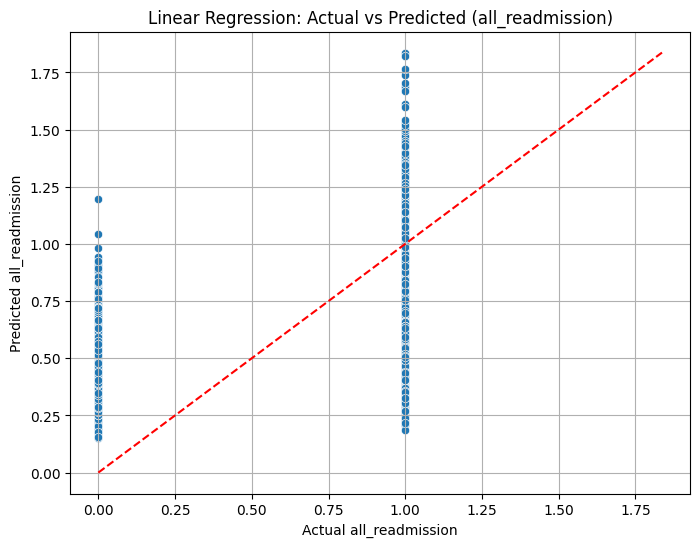

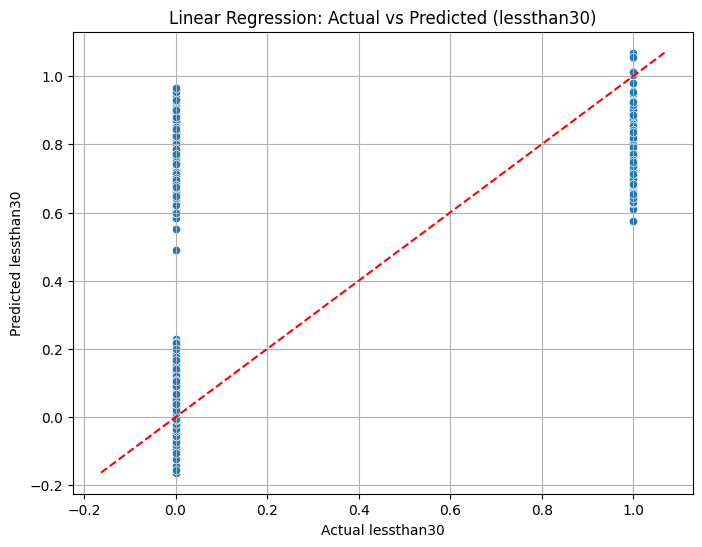

In [74]:
for target in ['all_readmission', 'lessthan30']:

    y_valid = splits[target]['y_valid']
    y_valid_preds = predictions[target]

    plt.figure(figsize=(8,6))
    sns.scatterplot(x=y_valid, y=y_valid_preds)

    # 45-degree reference line
    min_val = min(y_valid.min(), y_valid_preds.min())
    max_val = max(y_valid.max(), y_valid_preds.max())
    plt.plot([min_val, max_val], [min_val, max_val], 
             color='red', linestyle='--')

    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Linear Regression: Actual vs Predicted ({target})")
    plt.grid(True)
    plt.show()


### Logistic Regression

In [75]:
def print_report(y_true, y_pred, threshold):
    y_pred_class = (y_pred >= threshold).astype(int)

    auc = roc_auc_score(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred_class)
    recall = recall_score(y_true, y_pred_class)
    precision = precision_score(y_true, y_pred_class)
    specificity = recall_score(y_true, y_pred_class, pos_label=0)
    prevalence = pd.Series(y_true).mean()

    return auc, acc, recall, precision, specificity, prevalence


# Logistic Regression for BOTH TARGETS with boxed output
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train logistic regression
    lr = LogisticRegression(
        random_state=42,
        solver='newton-cg',
        max_iter=200
    )
    lr.fit(X_train, y_train)

    # predict probabilities
    y_valid_preds = lr.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, y_valid_preds, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" LOGISTIC REGRESSION METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 LOGISTIC REGRESSION METRICS — all_readmission 
 AUC:         0.7340
 Accuracy:    0.6851
 Recall:      0.4784
 Precision:   0.7499
 Specificity: 0.8628
 Prevalence:  0.4623


 LOGISTIC REGRESSION METRICS — lessthan30 
 AUC:         0.8299
 Accuracy:    0.6521
 Recall:      1.0000
 Precision:   0.2473
 Specificity: 0.6072
 Prevalence:  0.1143



### KNN Model

In [76]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train KNN
    knn = KNeighborsClassifier(n_neighbors=100)
    knn.fit(X_train, y_train)

    # predict probabilities
    knn_preds = knn.predict_proba(X_valid)[:, 1]

    # compute metrics (6 values)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, knn_preds, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" KNN METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 KNN METRICS — all_readmission 
 AUC:         0.6941
 Accuracy:    0.6524
 Recall:      0.4877
 Precision:   0.6706
 Specificity: 0.7940
 Prevalence:  0.4623


 KNN METRICS — lessthan30 
 AUC:         0.7985
 Accuracy:    0.6616
 Recall:      0.8579
 Precision:   0.2334
 Specificity: 0.6363
 Prevalence:  0.1143



### Stochastic Gradient Descent Model

In [77]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train SGDClassifier (logistic regression with SGD)
    sgdc = SGDClassifier(
        loss='log_loss',
        alpha=0.1,
        random_state=42
    )
    sgdc.fit(X_train, y_train)

    # predict probabilities
    sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, sgd_preds, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" SGD CLASSIFIER METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 SGD CLASSIFIER METRICS — all_readmission 
 AUC:         0.7138
 Accuracy:    0.6691
 Recall:      0.5654
 Precision:   0.6679
 Specificity: 0.7583
 Prevalence:  0.4623


 SGD CLASSIFIER METRICS — lessthan30 
 AUC:         0.8263
 Accuracy:    0.6723
 Recall:      0.9404
 Precision:   0.2510
 Specificity: 0.6377
 Prevalence:  0.1143



### Decision Tree

In [78]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train Decision Tree
    dc_clf = DecisionTreeClassifier(
        random_state=42,
        max_depth=10
    )
    dc_clf.fit(X_train, y_train)

    # predict probabilities
    dc_preds_proba = dc_clf.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, dc_preds_proba, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" DECISION TREE METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 DECISION TREE METRICS — all_readmission 
 AUC:         0.7311
 Accuracy:    0.6781
 Recall:      0.5695
 Precision:   0.6818
 Specificity: 0.7714
 Prevalence:  0.4623


 DECISION TREE METRICS — lessthan30 
 AUC:         0.8171
 Accuracy:    0.6586
 Recall:      0.9731
 Precision:   0.2474
 Specificity: 0.6180
 Prevalence:  0.1143



### Random Forest

In [79]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train Random Forest
    rf_clf = RandomForestClassifier(
        random_state=111,
        max_depth=6
    )
    rf_clf.fit(X_train, y_train)

    # predict probabilities
    rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, rf_preds_proba, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" RANDOM FOREST METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 RANDOM FOREST METRICS — all_readmission 
 AUC:         0.7430
 Accuracy:    0.6842
 Recall:      0.5580
 Precision:   0.6982
 Specificity: 0.7926
 Prevalence:  0.4623


 RANDOM FOREST METRICS — lessthan30 
 AUC:         0.8293
 Accuracy:    0.6520
 Recall:      1.0000
 Precision:   0.2473
 Specificity: 0.6071
 Prevalence:  0.1143



### Linear SVC

In [80]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train Linear SVC
    lsvc_clf = LinearSVC(
        random_state=111
    )
    lsvc_clf.fit(X_train, y_train)

    # decision_function gives continuous scores (good for AUC)
    lsvc_scores = lsvc_clf.decision_function(X_valid)

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, lsvc_scores, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" LINEAR SVC METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 LINEAR SVC METRICS — all_readmission 
 AUC:         0.7335
 Accuracy:    0.6621
 Recall:      0.2806
 Precision:   0.9607
 Specificity: 0.9901
 Prevalence:  0.4623


 LINEAR SVC METRICS — lessthan30 
 AUC:         0.8303
 Accuracy:    0.8639
 Recall:      0.2120
 Precision:   0.3451
 Specificity: 0.9481
 Prevalence:  0.1143



### Gradient Boosting Model

In [81]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train Gradient Boosting
    gb_clf = GradientBoostingClassifier(
        n_estimators=100,
        criterion='friedman_mse',
        learning_rate=1.0,
        max_depth=3,
        random_state=111
    )
    gb_clf.fit(X_train, y_train)

    # predict probabilities
    gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, gb_preds_proba, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" GRADIENT BOOSTING METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 GRADIENT BOOSTING METRICS — all_readmission 
 AUC:         0.7393
 Accuracy:    0.6788
 Recall:      0.5621
 Precision:   0.6863
 Specificity: 0.7791
 Prevalence:  0.4623


 GRADIENT BOOSTING METRICS — lessthan30 
 AUC:         0.8230
 Accuracy:    0.6733
 Recall:      0.9387
 Precision:   0.2513
 Specificity: 0.6391
 Prevalence:  0.1143



### XGB Model

In [82]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train XGBoost
    xgb_clf = xgb.XGBClassifier(
        max_depth=3,
        learning_rate=1.0,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=111
    )
    xgb_clf.fit(X_train, y_train)

    # predict probabilities
    xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, xgb_preds_proba, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" XGBOOST METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 XGBOOST METRICS — all_readmission 
 AUC:         0.7394
 Accuracy:    0.6812
 Recall:      0.5643
 Precision:   0.6898
 Specificity: 0.7818
 Prevalence:  0.4623


 XGBOOST METRICS — lessthan30 
 AUC:         0.8230
 Accuracy:    0.6729
 Recall:      0.9496
 Precision:   0.2525
 Specificity: 0.6372
 Prevalence:  0.1143



### Catboost Model

In [83]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # train CatBoost
    catb = CatBoostClassifier(
        iterations=200,
        depth=3,
        learning_rate=1.0,
        random_state=111,
        verbose=0   # silence CatBoost training output
    )
    catb.fit(X_train, y_train)

    # predict probabilities
    catb_preds = catb.predict_proba(X_valid)[:, 1]

    # compute metrics (NOW 6 VALUES)
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, catb_preds, 0.5
    )

    # print results in a box
    print("\n" + "="*50)
    print(f" CATBOOST METRICS — {target} ")
    print("="*50)
    print(f" AUC:         {auc:.4f}")
    print(f" Accuracy:    {acc:.4f}")
    print(f" Recall:      {recall:.4f}")
    print(f" Precision:   {precision:.4f}")
    print(f" Specificity: {specificity:.4f}")
    print(f" Prevalence:  {prevalence:.4f}")
    print("="*50 + "\n")



 CATBOOST METRICS — all_readmission 
 AUC:         0.7410
 Accuracy:    0.6814
 Recall:      0.5702
 Precision:   0.6874
 Specificity: 0.7770
 Prevalence:  0.4623


 CATBOOST METRICS — lessthan30 
 AUC:         0.8238
 Accuracy:    0.6761
 Recall:      0.9284
 Precision:   0.2516
 Specificity: 0.6435
 Prevalence:  0.1143



## Hyper Parameter Tuning

### Decision Tree

In [76]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # base model for RandomizedSearchCV
    dc_clf = DecisionTreeClassifier(random_state=42)

    # hyperparameter grid
    dc_grid = {
        'max_features': ['auto', 'sqrt'],
        'max_depth': range(1, 11, 1),
        'min_samples_split': range(2, 10, 2),
        'min_samples_leaf': range(1, 11, 2),
        'criterion': ['gini', 'entropy']
    }

    # randomized search
    dc_random = RandomizedSearchCV(
        estimator=dc_clf,
        param_distributions=dc_grid,
        n_iter=20,
        cv=10,
        scoring='recall',
        verbose=1,
        random_state=111
    )

    # fit hyperparameter search
    dc_random.fit(X_train, y_train)

    # best estimator predictions (class labels + probabilities)
    dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
    dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:, 1]

    # compute all 6 metrics
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, dc_hp_preds_proba, 0.5
    )

    # compute validation recall using class labels
    val_recall = recall_score(y_valid, dc_hp_preds)

    # ---------------------------------------------------------
    #FULL METRICS
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print(f" TUNED DECISION TREE METRICS — {target} ")
    print("="*50)
    print(f" Best Params:       {dc_random.best_params_}")
    print(f" Best CV Recall:    {dc_random.best_score_:.4f}")
    print("-"*50)
    print(f" AUC:               {auc:.4f}")
    print(f" Accuracy:          {acc:.4f}")
    print(f" Recall:            {recall:.4f}")
    print(f" Precision:         {precision:.4f}")
    print(f" Specificity:       {specificity:.4f}")
    print(f" Prevalence:        {prevalence:.4f}")
    print("="*50 + "\n")

    # ---------------------------------------------------------
    # VALIDATION RECALL ONLY
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print(f" TUNED DECISION TREE — VALIDATION RECALL — {target} ")
    print("="*50)
    print(f" Best Params:       {dc_random.best_params_}")
    print(f" Best CV Recall:    {dc_random.best_score_:.4f}")
    print(f" Validation Recall: {val_recall:.4f}")
    print("="*50 + "\n")


Fitting 10 folds for each of 20 candidates, totalling 200 fits

 TUNED DECISION TREE METRICS — all_readmission 
 Best Params:       {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
 Best CV Recall:    0.6054
--------------------------------------------------
 AUC:               0.5177
 Accuracy:          0.5052
 Recall:            0.6836
 Precision:         0.4756
 Specificity:       0.3519
 Prevalence:        0.4623


 TUNED DECISION TREE — VALIDATION RECALL — all_readmission 
 Best Params:       {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
 Best CV Recall:    0.6054
 Validation Recall: 0.6836

Fitting 10 folds for each of 20 candidates, totalling 200 fits

 TUNED DECISION TREE METRICS — lessthan30 
 Best Params:       {'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 5, 'criterion': 'gini'}
 Best CV Recall:    0.9493
----

### Random Forest

In [77]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # base model for tuning
    rf_clf = RandomForestClassifier(random_state=111)

    # hyperparameter grid
    rf_grid = {
        'n_estimators': range(200, 1000, 200),
        'max_features': ['auto', 'sqrt'],
        'max_depth': range(1, 11, 1),
        'min_samples_split': range(2, 10, 2),
        'criterion': ['gini', 'entropy']
    }

    # randomized search
    rf_random = RandomizedSearchCV(
        estimator=rf_clf,
        param_distributions=rf_grid,
        n_iter=20,
        cv=2,
        scoring=make_scorer(recall_score),
        verbose=1,
        random_state=111
    )

    # fit hyperparameter search
    rf_random.fit(X_train, y_train)

    # CLASS LABEL predictions (needed for recall_score)
    rf_hp_preds = rf_random.best_estimator_.predict(X_valid)

    # PROBABILITY predictions (needed for AUC + print_report)
    rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:, 1]

    # compute validation recall using class labels
    val_recall = recall_score(y_valid, rf_hp_preds)

    # compute all 6 metrics using probabilities
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, rf_hp_preds_proba, 0.5
    )

    # ---------------------------------------------------------
    # FULL METRICS
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print(f" TUNED RANDOM FOREST METRICS — {target} ")
    print("="*50)
    print(f" Best Params:        {rf_random.best_params_}")
    print(f" Best CV Recall:     {rf_random.best_score_:.4f}")
    print("-"*50)
    print(f" AUC:                {auc:.4f}")
    print(f" Accuracy:           {acc:.4f}")
    print(f" Recall:             {recall:.4f}")
    print(f" Precision:          {precision:.4f}")
    print(f" Specificity:        {specificity:.4f}")
    print(f" Prevalence:         {prevalence:.4f}")
    print("="*50 + "\n")

    # ---------------------------------------------------------
    # VALIDATION RECALL ONLY
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print(f" TUNED RANDOM FOREST — VALIDATION RECALL — {target} ")
    print("="*50)
    print(f" Best Params:        {rf_random.best_params_}")
    print(f" Best CV Recall:     {rf_random.best_score_:.4f}")
    print(f" Validation Recall:  {val_recall:.4f}")
    print("="*50 + "\n")


Fitting 2 folds for each of 20 candidates, totalling 40 fits

 TUNED RANDOM FOREST METRICS — all_readmission 
 Best Params:        {'n_estimators': 800, 'min_samples_split': 6, 'max_features': 'sqrt', 'max_depth': 8, 'criterion': 'gini'}
 Best CV Recall:     0.5180
--------------------------------------------------
 AUC:                0.7443
 Accuracy:           0.6879
 Recall:             0.5518
 Precision:          0.7086
 Specificity:        0.8049
 Prevalence:         0.4623


 TUNED RANDOM FOREST — VALIDATION RECALL — all_readmission 
 Best Params:        {'n_estimators': 800, 'min_samples_split': 6, 'max_features': 'sqrt', 'max_depth': 8, 'criterion': 'gini'}
 Best CV Recall:     0.5180
 Validation Recall:  0.5518

Fitting 2 folds for each of 20 candidates, totalling 40 fits

 TUNED RANDOM FOREST METRICS — lessthan30 
 Best Params:        {'n_estimators': 800, 'min_samples_split': 8, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
 Best CV Recall:     0.9787
----

### XGBoost

In [78]:
for target in ['all_readmission', 'lessthan30']:

    # pull the splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # base model for tuning
    xgb_clf = xgb.XGBClassifier(
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=111
    )

    # hyperparameter grid
    xgb_grid = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
    }

    # grid search
    xgb_random = GridSearchCV(
        estimator=xgb_clf,
        param_grid=xgb_grid,
        cv=2,
        scoring=make_scorer(recall_score),
        verbose=1
    )

    # fit tuning
    xgb_random.fit(X_train, y_train)

    # CLASS LABEL predictions (needed for recall_score)
    xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)

    # PROBABILITY predictions (needed for AUC + print_report)
    xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:, 1]

    # compute validation recall using class labels
    val_recall = recall_score(y_valid, xgb_hp_preds)

    # compute all 6 metrics using probabilities
    auc, acc, recall, precision, specificity, prevalence = print_report(
        y_valid, xgb_hp_preds_proba, 0.5
    )

    # ---------------------------------------------------------
    # FULL METRICS
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print(f" TUNED XGBOOST METRICS — {target} ")
    print("="*50)
    print(f" Best Params:        {xgb_random.best_params_}")
    print(f" Best CV Recall:     {xgb_random.best_score_:.4f}")
    print("-"*50)
    print(f" AUC:                {auc:.4f}")
    print(f" Accuracy:           {acc:.4f}")
    print(f" Recall:             {recall:.4f}")
    print(f" Precision:          {precision:.4f}")
    print(f" Specificity:        {specificity:.4f}")
    print(f" Prevalence:         {prevalence:.4f}")
    print("="*50 + "\n")

    # ---------------------------------------------------------
    # VALIDATION RECALL ONLY
    # ---------------------------------------------------------
    print("\n" + "="*50)
    print(f" TUNED XGBOOST — VALIDATION RECALL — {target} ")
    print("="*50)
    print(f" Best Params:        {xgb_random.best_params_}")
    print(f" Best CV Recall:     {xgb_random.best_score_:.4f}")
    print(f" Validation Recall:  {val_recall:.4f}")
    print("="*50 + "\n")


Fitting 2 folds for each of 720 candidates, totalling 1440 fits

 TUNED XGBOOST METRICS — all_readmission 
 Best Params:        {'colsample_bytree': 0.9, 'gamma': 1, 'max_depth': 5, 'min_child_weight': 8, 'subsample': 0.6}
 Best CV Recall:     0.5309
--------------------------------------------------
 AUC:                0.7398
 Accuracy:           0.6782
 Recall:             0.5502
 Precision:          0.6908
 Specificity:        0.7882
 Prevalence:         0.4623


 TUNED XGBOOST — VALIDATION RECALL — all_readmission 
 Best Params:        {'colsample_bytree': 0.9, 'gamma': 1, 'max_depth': 5, 'min_child_weight': 8, 'subsample': 0.6}
 Best CV Recall:     0.5309
 Validation Recall:  0.5502

Fitting 2 folds for each of 720 candidates, totalling 1440 fits

 TUNED XGBOOST METRICS — lessthan30 
 Best Params:        {'colsample_bytree': 1.0, 'gamma': 5, 'max_depth': 3, 'min_child_weight': 10, 'subsample': 1.0}
 Best CV Recall:     0.9067
--------------------------------------------------
 AU

## COMBINING RESULTS FOR NON HYPER PARAMETER TUNING

In [84]:
targets = ['all_readmission', 'lessthan30']

for target in targets:

    print("\n" + "="*70)
    print(f"     MODEL PERFORMANCE TABLE — {target.upper()} ")
    print("="*70)

    # pull splits for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # prevalence
    prev = y_valid.mean()

    # container for this target
    results = []

    def add_result(model_name, auc, acc, rec, prec, spec, prev):
        results.append({
            "Model": model_name,
            "AUC": auc,
            "Accuracy": acc,
            "Recall": rec,
            "Precision": prec,
            "Specificity": spec,
            "Prevalence": prev
        })

    # ============================================================
    # 1. Logistic Regression
    # ============================================================
    lr = LogisticRegression(random_state=42, solver='newton-cg', max_iter=200)
    lr.fit(X_train, y_train)
    lr_preds = lr.predict_proba(X_valid)[:, 1]
    lr_auc, lr_acc, lr_rec, lr_prec, lr_spec, _ = print_report(y_valid, lr_preds, 0.5)
    add_result("Logistic Regression", lr_auc, lr_acc, lr_rec, lr_prec, lr_spec, prev)

    # ============================================================
    # 2. KNN
    # ============================================================
    knn = KNeighborsClassifier(n_neighbors=100)
    knn.fit(X_train, y_train)
    knn_preds = knn.predict_proba(X_valid)[:, 1]
    knn_auc, knn_acc, knn_rec, knn_prec, knn_spec, _ = print_report(y_valid, knn_preds, 0.5)
    add_result("KNN (k=100)", knn_auc, knn_acc, knn_rec, knn_prec, knn_spec, prev)

    # ============================================================
    # 3. SGDClassifier
    # ============================================================
    sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
    sgdc.fit(X_train, y_train)
    sgdc_preds = sgdc.predict_proba(X_valid)[:, 1]
    sgdc_auc, sgdc_acc, sgdc_rec, sgdc_prec, sgdc_spec, _ = print_report(y_valid, sgdc_preds, 0.5)
    add_result("SGDClassifier", sgdc_auc, sgdc_acc, sgdc_rec, sgdc_prec, sgdc_spec, prev)

    # ============================================================
    # 4. Decision Tree
    # ============================================================
    dc_clf = DecisionTreeClassifier(random_state=42, max_depth=10)
    dc_clf.fit(X_train, y_train)
    dc_preds = dc_clf.predict_proba(X_valid)[:, 1]
    dc_auc, dc_acc, dc_rec, dc_prec, dc_spec, _ = print_report(y_valid, dc_preds, 0.5)
    add_result("Decision Tree (max_depth=10)", dc_auc, dc_acc, dc_rec, dc_prec, dc_spec, prev)

    # ============================================================
    # 5. Random Forest
    # ============================================================
    rf_clf = RandomForestClassifier(random_state=111, max_depth=6)
    rf_clf.fit(X_train, y_train)
    rf_preds = rf_clf.predict_proba(X_valid)[:, 1]
    rf_auc, rf_acc, rf_rec, rf_prec, rf_spec, _ = print_report(y_valid, rf_preds, 0.5)
    add_result("Random Forest (max_depth=6)", rf_auc, rf_acc, rf_rec, rf_prec, rf_spec, prev)

    # ============================================================
    # 6. Linear SVC
    # ============================================================
    lsvc_clf = LinearSVC(random_state=111)
    lsvc_clf.fit(X_train, y_train)
    lsvc_preds = lsvc_clf.decision_function(X_valid)
    lsvc_auc, lsvc_acc, lsvc_rec, lsvc_prec, lsvc_spec, _ = print_report(y_valid, lsvc_preds, 0.5)
    add_result("Linear SVC", lsvc_auc, lsvc_acc, lsvc_rec, lsvc_prec, lsvc_spec, prev)

    # ============================================================
    # 7. Gradient Boosting
    # ============================================================
    gb_clf = GradientBoostingClassifier(
        n_estimators=100,
        criterion='friedman_mse',
        learning_rate=1.0,
        max_depth=3,
        random_state=111
    )
    gb_clf.fit(X_train, y_train)
    gb_preds = gb_clf.predict_proba(X_valid)[:, 1]
    gb_auc, gb_acc, gb_rec, gb_prec, gb_spec, _ = print_report(y_valid, gb_preds, 0.5)
    add_result("Gradient Boosting", gb_auc, gb_acc, gb_rec, gb_prec, gb_spec, prev)

    # ============================================================
    # 8. XGBoost
    # ============================================================
    xgb_clf = xgb.XGBClassifier(
        max_depth=3,
        learning_rate=1.0,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    xgb_clf.fit(X_train, y_train)
    xgb_preds = xgb_clf.predict_proba(X_valid)[:, 1]
    xgb_auc, xgb_acc, xgb_rec, xgb_prec, xgb_spec, _ = print_report(y_valid, xgb_preds, 0.5)
    add_result("XGBoost", xgb_auc, xgb_acc, xgb_rec, xgb_prec, xgb_spec, prev)

    # ============================================================
    # 9. CatBoost
    # ============================================================
    catb = CatBoostClassifier(
        iterations=200,
        depth=3,
        learning_rate=1.0,
        random_state=111,
        verbose=False
    )
    catb.fit(X_train, y_train)
    catb_preds = catb.predict_proba(X_valid)[:, 1]
    catb_auc, catb_acc, catb_rec, catb_prec, catb_spec, _ = print_report(y_valid, catb_preds, 0.5)
    add_result("CatBoost", catb_auc, catb_acc, catb_rec, catb_prec, catb_spec, prev)

    # ============================================================
    # FINAL TABLE FOR THIS TARGET
    # ============================================================
    results_df = pd.DataFrame(results)
    print(results_df)
    print("\n" + "="*70 + "\n")



     MODEL PERFORMANCE TABLE — ALL_READMISSION 
                          Model       AUC  Accuracy    Recall  Precision  \
0           Logistic Regression  0.734010  0.685076  0.478390   0.749889   
1                   KNN (k=100)  0.694061  0.652385  0.487743   0.670563   
2                 SGDClassifier  0.713776  0.669091  0.565396   0.667894   
3  Decision Tree (max_depth=10)  0.731051  0.678066  0.569505   0.681764   
4   Random Forest (max_depth=6)  0.743043  0.684159  0.558027   0.698227   
5                    Linear SVC  0.733479  0.662081  0.280572   0.960699   
6             Gradient Boosting  0.739270  0.678787  0.562137   0.686332   
7                       XGBoost  0.739428  0.681211  0.564262   0.689763   
8                      CatBoost  0.740983  0.681407  0.570214   0.687393   

   Specificity  Prevalence  
0     0.862800     0.46233  
1     0.793956     0.46233  
2     0.758255     0.46233  
3     0.771415     0.46233  
4     0.792616     0.46233  
5     0.990130  

## RESULTS

Summary
This analysis compared three imbalance handling techniques: SMOTE, Random Oversampling, and Random Undersampling, across three feature sets and nine machine learning models to identify the strongest approach for predicting hospital readmission. Performance was evaluated using AUC, accuracy, recall, precision, and specificity.

# SMOTE
When we used SMOTE to balance the data, the models behaved differently for the two targets. For all_readmission, the models did okay but not amazing. Their AUC scores were in the low‑to‑mid 0.70s, which means they can tell the difference between patients who will be readmitted and those who won’t, but only moderately well. Most models caught about half of the real readmissions (recall around 0.53–0.57), which is normal because this outcome is influenced by many different factors. Precision was fairly high, meaning that when the model predicted a readmission, it was usually right. Tree‑based models like Random Forest, Gradient Boosting, XGBoost, and CatBoost performed the best overall.

For lessthan30, which is a much rarer event, SMOTE helped a lot more. The AUC scores were higher (around 0.77–0.81), showing that the models could separate the two classes better. The biggest improvement was in recall: Random Forest was able to catch more than 80% of the 30‑day readmissions, which is very strong. However, precision stayed low for all models because the real number of 30‑day readmissions is small, so the models made more false alarms. Overall, SMOTE made the models much better at finding the rare 30‑day readmissions, even though it caused precision to drop. Tree‑based models again gave the best balance of performance.

# Random Oversampling
When we used Random Oversampling, the models behaved differently for the two outcomes. For all_readmission, the results were fairly steady across models. The AUC scores stayed in the low‑to‑mid 0.70s, which means the models can tell the difference between patients who will be readmitted and those who won’t, but only at a moderate level. Most models reached recall values around 0.56, meaning they caught a little more than half of the real readmissions. Precision stayed pretty high, especially for Linear SVC, although that model missed many actual readmissions because its recall was low. Overall, tree‑based models like Random Forest, Gradient Boosting, XGBoost, and CatBoost gave the most balanced performance for this target.

For lessthan30, oversampling had a much bigger impact because this outcome is rare in the original data. The AUC scores were higher (around 0.82–0.83), showing that the models could separate the two classes better than they could for all_readmission. The biggest change was in recall: several models, including Logistic Regression and Random Forest, reached perfect recall (1.00), meaning they caught every single 30‑day readmission in the validation set. However, this came with low precision (around 0.24–0.25), which means the models also produced many false alarms. This tradeoff is normal when oversampling a rare class—the model becomes very sensitive but less precise. Tree‑based models again performed well overall, and the results show that oversampling is especially helpful for improving recall on rare outcomes like 30‑day readmissions.

# Random Undersampling
When we used Random Undersampling, the models showed patterns similar to oversampling, but with slightly more stable and consistent results. For all_readmission, the models performed at a moderate level, with AUC scores mostly in the low‑to‑mid 0.70s. This means the models could tell the difference between patients who would be readmitted and those who wouldn’t, but not extremely well. Most models reached recall values around 0.56–0.57, meaning they caught a little more than half of the real readmissions. Precision stayed fairly high, especially for Linear SVC, although that model again missed many actual readmissions because its recall was low. Tree‑based models like Random Forest, Gradient Boosting, XGBoost, and CatBoost continued to give the most balanced performance. Overall, undersampling didn’t hurt the models much for this target because the original dataset was already close to balanced.

For lessthan30, which is a rare outcome, undersampling had a big impact—similar to oversampling. The AUC scores were strong (around 0.82–0.83), showing that the models could separate the two classes well. Recall was extremely high for many models, with Logistic Regression and Random Forest reaching perfect recall (1.00), meaning they caught every single 30‑day readmission. However, precision stayed low (around 0.24–0.25) because the model made many false alarms. This is normal when the minority class is oversampled or the majority class is undersampled—the model becomes very sensitive but less precise. Tree‑based models again performed well overall. In short, undersampling helped the models find almost all of the rare 30‑day readmissions, but at the cost of predicting too many positives.


Recommendations
For the all_readmission target, the best imbalance technique is Random Undersampling, since it performs just as well as SMOTE and Oversampling but is simpler and more stable. The strongest model for this target is Random Forest, which reaches an AUC of about 0.743, a recall of around 0.56, and a precision of roughly 0.69. If your main goal is to maximize recall, the SGDClassifier performs slightly higher at about 0.57, though it comes with a lower AUC. 

For the lessthan30 target, the best imbalance technique depends on your goal: choose SMOTE if you want balanced performance across metrics, or choose Oversampling/Undersampling if your priority is catching as many true 30‑day readmissions as possible. The best overall model for this target is CatBoost, with an AUC of about 0.83, recall around 0.94, and precision near 0.25. If maximum recall is the priority, Random Forest is the top choice, achieving a perfect recall of 1.00, an AUC of about 0.83, and a precision of roughly 0.24. 

In short, use Undersampling + Random Forest for all_readmission, use SMOTE + CatBoost for lessthan30, and switch to Oversampling or Undersampling + Random Forest if your goal is to catch every possible 30‑day readmission.
